In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

data = [
  {
    "name": "Control",
    "mean": 540.59,
    "median": 542.0,
  },
  {
    'name': 'Full APTES Treated',
    'mean': 614.41,
    'median': 617.0,
  },
  {
    'name': 'Half APTES Treated Position 1; Treated Region Only',
    'mean': 615.55,
    'median': 616.0,
  },
  {
    'name': 'Half APTES Treated Position 1; Untreated Region Only',
    'mean': 540.59,
    'median': 542.0,
  },
  {
    'name': 'Half APTES Treated Position 2; Treated Region Only',
    'mean': 589.32,
    'median': 591.0,
  },
  {
    'name': 'Half APTES Treated Position 2; Untreated Region Only',
    'mean': 548.9,
    'median': 550.0,
  },
]

df = pd.DataFrame(data)

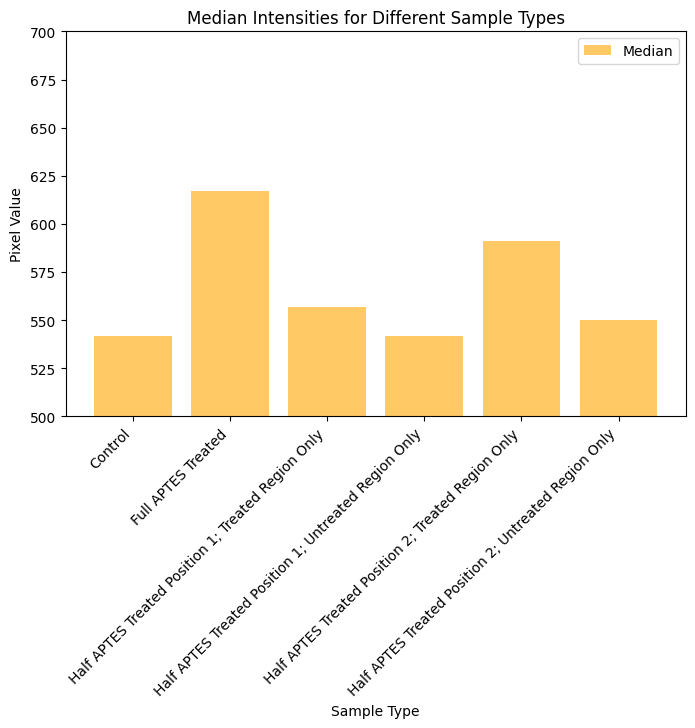

In [7]:
plt.figure(figsize=(8, 5))
plt.bar(df['name'], df['median'], color='orange', alpha=0.6, label='Median')
plt.xlabel('Sample Type')
plt.ylabel('Pixel Value')
plt.ylim(500, 700)
plt.title('Median Intensities for Different Sample Types')
plt.xticks(rotation=45, ha='right')
plt.legend()

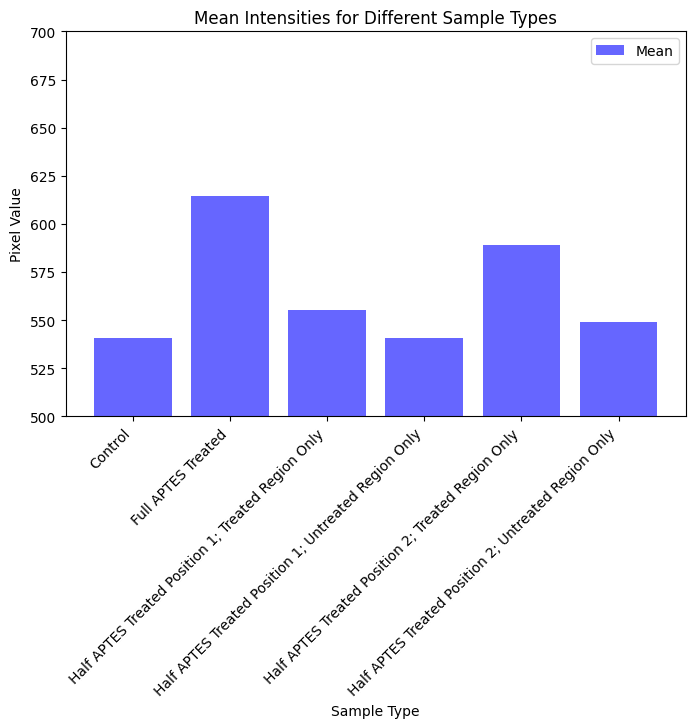

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(df['name'], df['mean'], color='blue', alpha=0.6, label='Mean')

plt.xlabel('Sample Type')
plt.ylabel('Pixel Value')
plt.ylim(500, 700)
plt.title('Mean Intensities for Different Sample Types')
plt.xticks(rotation=45, ha='right')
plt.legend()

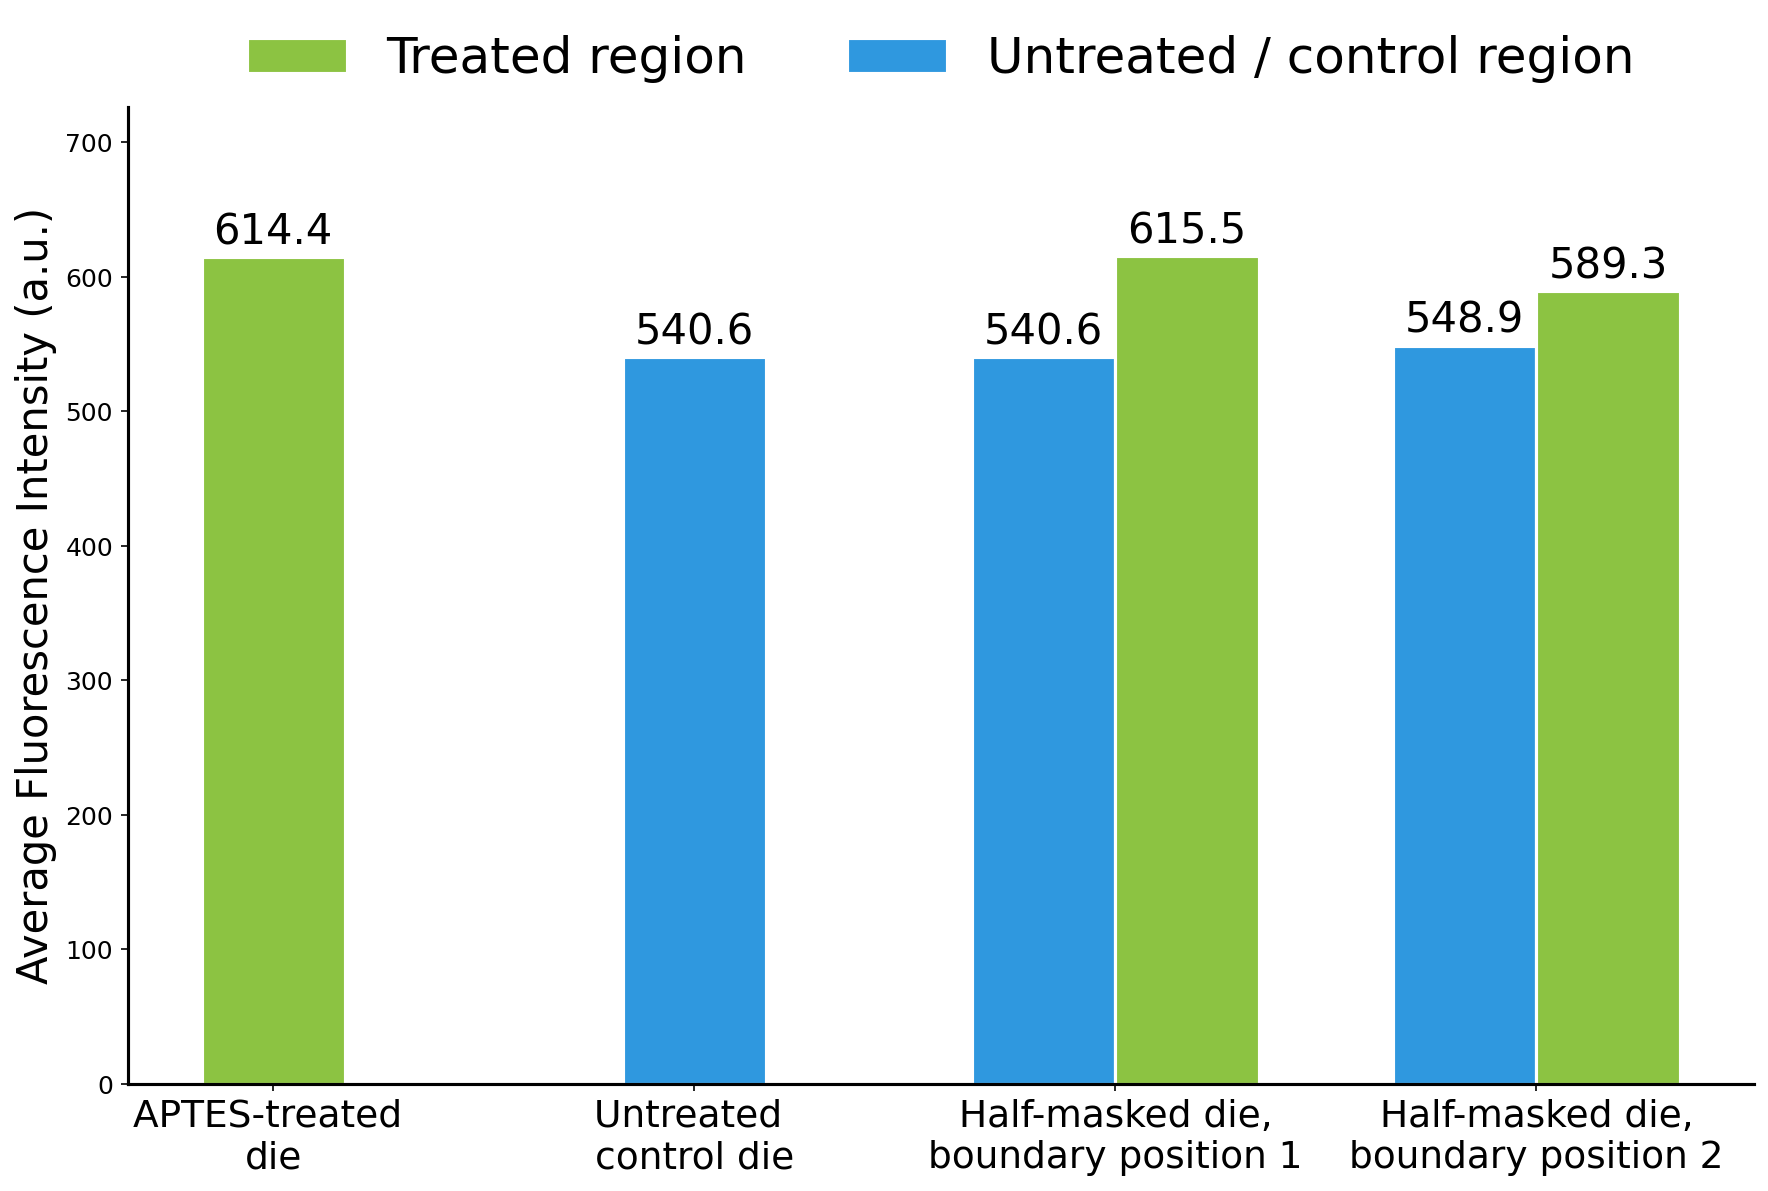

In [13]:
df = pd.DataFrame(data)

groups = [
    "APTES-treated \ndie",
    "Untreated \ncontrol die",
    "Half-masked die,\nboundary position 1",
    "Half-masked die,\nboundary position 2",
]

x = np.arange(len(groups))
width = 0.34

fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

# Values
full_treated = df.loc[df["name"] == "Full APTES Treated", "mean"].iloc[0]
control = df.loc[df["name"] == "Control", "mean"].iloc[0]

p1_treated = df.loc[df["name"].str.contains("Position 1; Treated"), "mean"].iloc[0]
p1_untreated = df.loc[df["name"].str.contains("Position 1; Untreated"), "mean"].iloc[0]

p2_treated = df.loc[df["name"].str.contains("Position 2; Treated"), "mean"].iloc[0]
p2_untreated = df.loc[df["name"].str.contains("Position 2; Untreated"), "mean"].iloc[0]

# Single bars for full treated and control
bars_full = ax.bar(
    x[0],
    full_treated,
    width,
    label="Treated region",
    color="#8cc342",
    edgecolor="white",
    linewidth=1.5,
)

bars_control = ax.bar(
    x[1],
    control,
    width,
    label="Untreated / control region",
    color="#2f98df",
    edgecolor="white",
    linewidth=1.5,
)

# Paired bars for half-masked dies
bars_p1_untreated = ax.bar(
    x[2] - width / 2,
    p1_untreated,
    width,
    color="#2f98df",
    edgecolor="white",
    linewidth=1.5,
)

bars_p1_treated = ax.bar(
    x[2] + width / 2,
    p1_treated,
    width,
    color="#8cc342",
    edgecolor="white",
    linewidth=1.5,
)

bars_p2_untreated = ax.bar(
    x[3] - width / 2,
    p2_untreated,
    width,
    color="#2f98df",
    edgecolor="white",
    linewidth=1.5,
)

bars_p2_treated = ax.bar(
    x[3] + width / 2,
    p2_treated,
    width,
    color="#8cc342",
    edgecolor="white",
    linewidth=1.5,
)

ax.set_ylabel("Average Fluorescence Intensity (a.u.)", fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=18)
ax.tick_params(axis="y", labelsize=12)

# ax.grid(axis="y", color="#d9d9d9", linewidth=1.2)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    frameon=False,
    fontsize=24,
)

for bars in [
    bars_full,
    bars_control,
    bars_p1_untreated,
    bars_p1_treated,
    bars_p2_untreated,
    bars_p2_treated,
]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 3,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=20,
        )

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.set_ylim(0, max(df["mean"]) * 1.18)

plt.tight_layout()
plt.show()